# GLM analysis

### Loading libraries and data

In [1]:
import os
import os.path as op

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

from nilearn.glm.first_level import FirstLevelModel
from nilearn.plotting import plot_design_matrix

In [2]:
# Project directories
notebook_dir = os.path.abspath("")
dataset_path = op.join(notebook_dir, 'dataset')

derivatives_func = op.join(dataset_path, 'derivatives', 'func')

# Load preprocessed fMRI data
fmri_path = op.join(
    derivatives_func,
    'tfMRI_LANGUAGE_LR_moco_smoothed-4mm.nii.gz'
)

fmri_img = nib.load(fmri_path)

# Acquisition parameters
tr = float(fmri_img.header.get_zooms()[3])
n_scans = fmri_img.shape[-1]

print("fMRI shape:", fmri_img.shape)
print("TR:", tr, "s")

fMRI shape: (91, 109, 91, 311)
TR: 0.7200000286102295 s


### Experimental design

The GLM includes two task regressors, `story` and `math`, representing
the main experimental conditions.

The event timings are adjusted to account for the first five fMRI
volumes removed during preprocessing.

In [3]:
# Load experimental events
events_path = op.join(
    dataset_path,
    'fMRI',
    'tfMRI_LANGUAGE_LR',
    'tfMRI_LANGUAGE_LR_task_onsets.csv'
)

events = pd.read_csv(events_path)

# Select the main experimental conditions
events_glm = events[
    events['trial_type'].isin(['math', 'story'])
].copy()

# Account for the first 5 volumes removed during preprocessing
start_vol = 5
time_shift = start_vol * tr

events_glm['onset'] = events_glm['onset'] - time_shift

# Remove events ending before the retained acquisition
events_glm = events_glm[
    events_glm['onset'] + events_glm['duration'] > 0
].copy()

# Adjust events overlapping the beginning
events_glm['duration'] = (
    events_glm['onset'] + events_glm['duration']
).clip(lower=0) - events_glm['onset'].clip(lower=0)

events_glm['onset'] = events_glm['onset'].clip(lower=0)

# Sort events
events_glm = events_glm.sort_values('onset').reset_index(drop=True)

events_glm

,onset,duration,trial_type
0,0.000,24.911,story
1,26.495,12.241,math
2,38.970,12.312,math
3,52.924,27.147,story
4,81.606,12.667,math
5,94.520,12.542,math
6,108.674,26.070,story
7,136.330,11.844,math
8,148.445,12.528,math
9,161.253,9.838,math


### GLM specification and estimation

A first-level GLM is fitted to the preprocessed fMRI data using Nilearn.

The experimental regressors are convolved with the canonical SPM
hemodynamic response function (HRF).

Temporal autocorrelation in the residuals is modeled using an AR(1)
noise model.

In [4]:
# Specify the GLM
fmri_glm = FirstLevelModel(
    t_r=tr,
    noise_model='ar1',
    standardize=False,
    hrf_model='spm',
    drift_model=None
)

# Fit the GLM
fmri_glm = fmri_glm.fit(fmri_img, events_glm)

### Design matrix

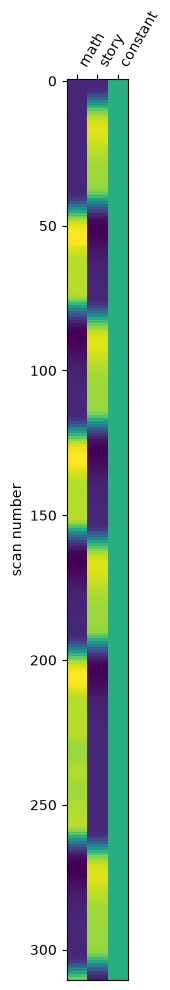

In [5]:
# Extract and visualize the design matrix
design_matrix = fmri_glm.design_matrices_[0]

plot_design_matrix(design_matrix)
plt.show()

### Correlation matrix

The correlation matrix is computed to assess the linear dependence
between the regressors of the design matrix.

High correlations between regressors may indicate multicollinearity,
making it more difficult to estimate their individual contributions
to the BOLD signal.

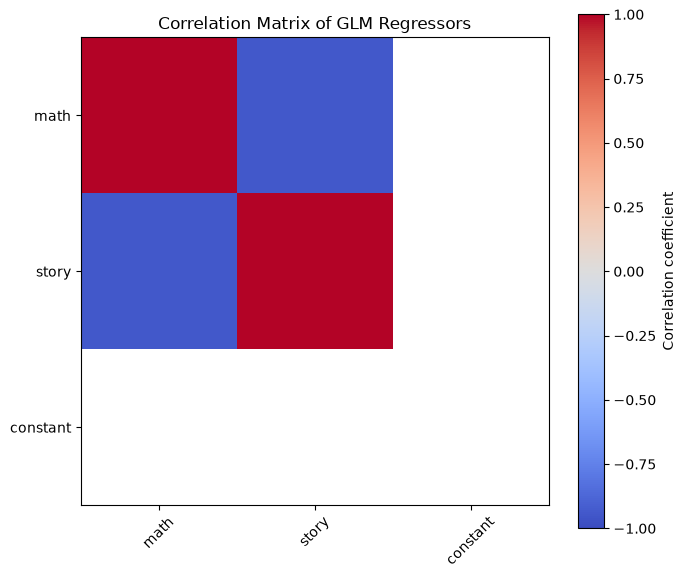

Correlation between math and story: -0.9425576755552469


In [6]:
# Compute correlation matrix
correlation_matrix = design_matrix.corr()

# Plot correlation matrix
plt.figure(figsize=(7, 6))

plt.imshow(
    correlation_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.colorbar(label='Correlation coefficient')

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title('Correlation Matrix of GLM Regressors')

plt.tight_layout()
plt.show()

# Correlation between the main task regressors
print(
    "Correlation between math and story:",
    correlation_matrix.loc['math', 'story']
)

### Interpretation

The correlation matrix shows a strong negative correlation between the math and story regressors (r = −0.943). This is consistent with the experimental design, in which the two conditions alternate over time and are largely mutually exclusive.

Such a strong anticorrelation indicates that the two regressors contain limited independent information, which can make it more difficult to estimate their individual effects. The reason is that, since the two conditions are almost complementary, it becomes difficult for the GLM to distinguish how much of the BOLD signal should be attributed to each condition and how much to the baseline (represented by the constant regressor). This can increase the uncertainty of the estimated coefficients.

However, this does not necessarily affect the direct comparison between the two conditions. Even if their individual contributions are difficult to separate from the baseline, their difference can still be estimated, because the baseline contribution cancels out when computing the story − math contrast.

The diagonal elements of the correlation matrix are equal to 1, since each nonconstant regressor is perfectly correlated with itself. Correlations involving the constant regressor are undefined because it has zero variance.

Overall, the correlation structure reflects the alternating block design. Although the strong anticorrelation may reduce the precision of individual coefficient estimates, it does not invalidate the GLM and still allows a meaningful comparison between mathematical and language processing through the story − math contrast.